### This example simulates a binary classification case (same dataset as before, but target converted to binary)

In [1]:
import shap
import xgboost as xgb
import pandas as pd
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np

# load data
df = pd.read_csv("../lifestyle_sustainability_data.csv")

df.head()


c:\Users\tuomas.valtanen\dataeng_advda2026_lectures\DataEngineering_AdvDA_2026\.venv\Lib\site-packages\xgboost\compat.py:105: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


,ParticipantID,Age,Location,DietType,LocalFoodFrequency,TransportationMode,EnergySource,HomeType,HomeSize,ClothingFrequency,SustainableBrands,EnvironmentalAwareness,CommunityInvolvement,MonthlyElectricityConsumption,MonthlyWaterConsumption,Gender,UsingPlasticProducts,DisposalMethods,PhysicalActivities,Rating
0,1,35,Urban,Mostly Plant-Based,Often,Bike,Renewable,Apartment,800,Rarely,True,5,High,100,1500,Female,Rarely,Composting,High,5
1,2,28,Suburban,Balanced,Sometimes,Public Transit,Mixed,House,1500,Sometimes,True,4,Moderate,250,3000,Male,Sometimes,Recycling,Moderate,4
2,3,65,Rural,Mostly Animal-Based,Rarely,Car,Non-Renewable,House,2500,Often,False,2,Low,400,4500,Male,Often,Landfill,Low,1
3,4,42,Urban,Mostly Plant-Based,Often,Walk,Renewable,Apartment,950,Sometimes,True,4,Moderate,150,2000,Female,Rarely,Recycling,High,5
4,5,31,Suburban,Balanced,Sometimes,Public Transit,Mixed,House,1800,Often,True,3,Low,300,3500,Non-Binary,Sometimes,Combination,Moderate,3


### See the apriori -example for the reasoning on how to handle these categories

In [2]:
# this just converts the value of column to 0 or 1
# factorize in pandas works too, but only one column at a time
from sklearn.preprocessing import LabelEncoder
variables = ["SustainableBrands"]
encoder = LabelEncoder()
df[variables] = df[variables].apply(encoder.fit_transform)

In [3]:
 # this example is using the housing data from Moodle
varlist_three = ["CommunityInvolvement", "PhysicalActivities"]
varlist_four = ["LocalFoodFrequency", "ClothingFrequency", "UsingPlasticProducts"]

# Defining the map function
def binary_map_three(x):
    return x.map({'Low': 0, "Moderate": 1, "High": 2})

# Defining the map function
def binary_map_four(x):
    return x.map({'Rarely': 0, "Sometimes": 1, "Often": 2, "Always": 3})

# Applying the function to the housing list
df[varlist_three] = df[varlist_three].apply(binary_map_three)
df[varlist_four] = df[varlist_four].apply(binary_map_four)

In [4]:
 # this makes multiple columns with the variable (Separate for yes/no)
from sklearn.preprocessing import OneHotEncoder
variables = ["Location", "DietType", "TransportationMode", "EnergySource", "HomeType", "Gender", "DisposalMethods"]

# use encoder
encoder = OneHotEncoder(sparse_output=False).set_output(transform="pandas")
one_hot_encoded = encoder.fit_transform(df[variables]).astype(int)
df = pd.concat([df,one_hot_encoded],axis=1).drop(columns=variables)

In [5]:
df.isna().sum()

ParticipantID                          0
Age                                    0
LocalFoodFrequency                     0
HomeSize                               0
ClothingFrequency                      0
SustainableBrands                      0
EnvironmentalAwareness                 0
CommunityInvolvement                 118
MonthlyElectricityConsumption          0
MonthlyWaterConsumption                0
UsingPlasticProducts                  95
PhysicalActivities                   108
Rating                                 0
Location_Rural                         0
Location_Suburban                      0
Location_Urban                         0
DietType_Balanced                      0
DietType_Mostly Animal-Based           0
DietType_Mostly Plant-Based            0
TransportationMode_Bike                0
TransportationMode_Car                 0
TransportationMode_Public Transit      0
TransportationMode_Walk                0
EnergySource_Mixed                     0
EnergySource_Non

In [6]:
df.columns

Index(['ParticipantID', 'Age', 'LocalFoodFrequency', 'HomeSize',
       'ClothingFrequency', 'SustainableBrands', 'EnvironmentalAwareness',
       'CommunityInvolvement', 'MonthlyElectricityConsumption',
       'MonthlyWaterConsumption', 'UsingPlasticProducts', 'PhysicalActivities',
       'Rating', 'Location_Rural', 'Location_Suburban', 'Location_Urban',
       'DietType_Balanced', 'DietType_Mostly Animal-Based',
       'DietType_Mostly Plant-Based', 'TransportationMode_Bike',
       'TransportationMode_Car', 'TransportationMode_Public Transit',
       'TransportationMode_Walk', 'EnergySource_Mixed',
       'EnergySource_Non-Renewable', 'EnergySource_Renewable',
       'HomeType_Apartment', 'HomeType_House', 'HomeType_Other',
       'Gender_Female', 'Gender_Male', 'Gender_Non-Binary',
       'Gender_Prefer not to say', 'DisposalMethods_Combination',
       'DisposalMethods_Composting', 'DisposalMethods_Landfill',
       'DisposalMethods_Recycling'],
      dtype='object')

### Handle some missing values, these are highly assuming replacement values, but we don't have much data to work with.... probably something fancier should be used here

In [7]:
# CommunityInvolvement                 118
# UsingPlasticProducts                  95
# PhysicalActivities                   108

df['CommunityInvolvement'] = df['CommunityInvolvement'].fillna(0.0)
df['UsingPlasticProducts'] = df['UsingPlasticProducts'].fillna(3.0)
df['PhysicalActivities'] = df['PhysicalActivities'].fillna(0.0)

In [8]:
# replace missing community involvement with 0
# replace missing using plastic products with 3
# replace missing physical activities with 0


In [9]:
# we can always remove one of the onehotencoded variables, 
# remove: 'DietType_Mostly Plant-Based',  'TransportationMode_Walk',  'EnergySource_Renewable', 'HomeType_Other', 'Gender_Prefer not to say', 'DisposalMethods_Recycling'
removables = ['DietType_Mostly Plant-Based',  'TransportationMode_Walk',  'EnergySource_Renewable', 'HomeType_Other', 'Gender_Prefer not to say', 'DisposalMethods_Recycling']
df = df.drop(removables, axis=1)

In [10]:
df.isna().sum().sum()

np.int64(0)

In [11]:
# XGBoost requires ordinals to be from 0 onwards
# let's fix that
df['Rating'] = df['Rating'] - 1.0

In [12]:
df['Rating'] = df['Rating'].astype(int)
#df['Rating'] = "Class " + df['Rating'].astype(str)

In [13]:
df['Rating'].value_counts()

Rating
4    176
2    101
0     97
3     91
1     34
Name: count, dtype: int64

In [14]:
df.head()

,ParticipantID,Age,LocalFoodFrequency,HomeSize,ClothingFrequency,SustainableBrands,EnvironmentalAwareness,CommunityInvolvement,MonthlyElectricityConsumption,MonthlyWaterConsumption,...,EnergySource_Mixed,EnergySource_Non-Renewable,HomeType_Apartment,HomeType_House,Gender_Female,Gender_Male,Gender_Non-Binary,DisposalMethods_Combination,DisposalMethods_Composting,DisposalMethods_Landfill
0,1,35,2,800,0,1,5,2.0,100,1500,...,0,0,1,0,1,0,0,0,1,0
1,2,28,1,1500,1,1,4,1.0,250,3000,...,1,0,0,1,0,1,0,0,0,0
2,3,65,0,2500,2,0,2,0.0,400,4500,...,0,1,0,1,0,1,0,0,0,1
3,4,42,2,950,1,1,4,1.0,150,2000,...,0,0,1,0,1,0,0,0,0,0
4,5,31,1,1800,2,1,3,0.0,300,3500,...,1,0,0,1,0,0,1,1,0,0


**Binary classification needs changes to the further SHAP visualizations...**

In [15]:
def convert_to_binary(row):
    if row['Rating'] <= 1:
        return 0
    else:
        return 1
    

df['Rating'] = df.apply(convert_to_binary, axis=1)

In [16]:
# handle these better with your own dataset, here we are simply dropping these
df = df.drop(['ParticipantID'], axis=1)

## SHAP analysis, it's a bit different when it comes to classification

Background dataset has 399 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=399 when initializing the masker.


[10:38:26] WARNING: C:/Users/administrator/workspace/xgboost-win64_release_1.6.0/src/learner.cc:627: 
Parameters: { "device" } might not be used.

  This could be a false alarm, with some parameters getting used by language bindings but
  then being mistakenly passed down to XGBoost core, or some parameter actually being used
  but getting flagged wrongly here. Please open an issue if you find any such cases.




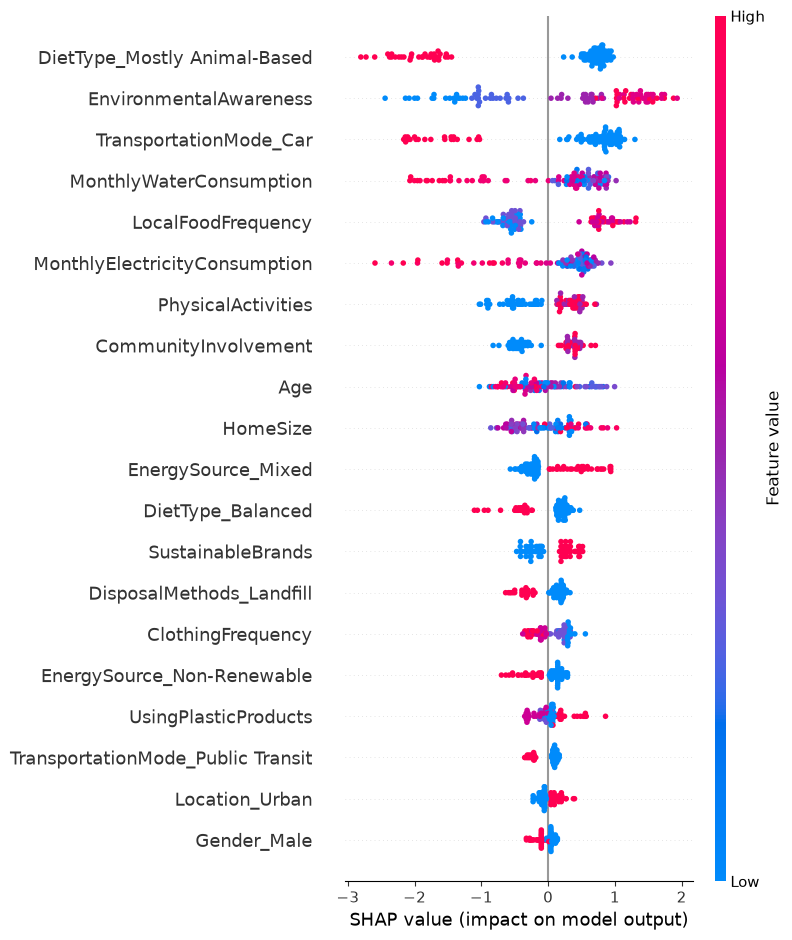

In [17]:
# Define features and target
X = df.drop("Rating", axis=1)

y = df['Rating']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# use GPU-enabled XGBoost Regressor
# model = xgb.XGBClassifier(tree_method='gpu_hist', objective="multi:softproba", num_class=2)
model = xgb.XGBClassifier(tree_method='hist',
    device='cuda', objective="binary:logistic")
model.fit(X_train, y_train)

# create SHAP explainer and values
explainer = shap.Explainer(model, X_train)
shap_values = explainer(X_test, check_additivity=False)

# summary plot
shap.summary_plot(shap_values, X_test)

___

### More experimental additional SHAP visualizations

Combination of AI, documentation and Googling

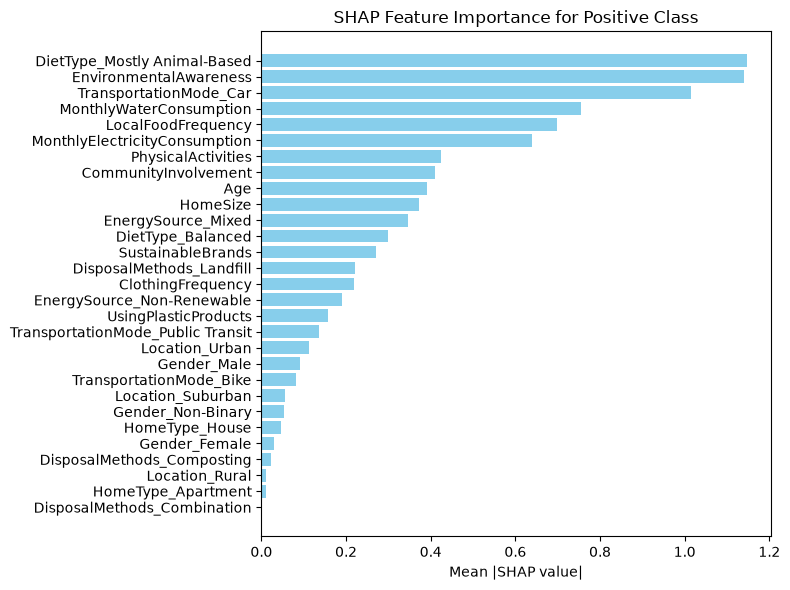

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

mean_abs_shap = np.mean(np.abs(shap_values.values), axis=0)

importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': mean_abs_shap
}).sort_values(by='Importance', ascending=True)

plt.figure(figsize=(8, 6))
plt.barh(importance_df['Feature'], importance_df['Importance'], color='skyblue')
plt.title('SHAP Feature Importance for Positive Class')
plt.xlabel('Mean |SHAP value|')
plt.tight_layout()
plt.show()


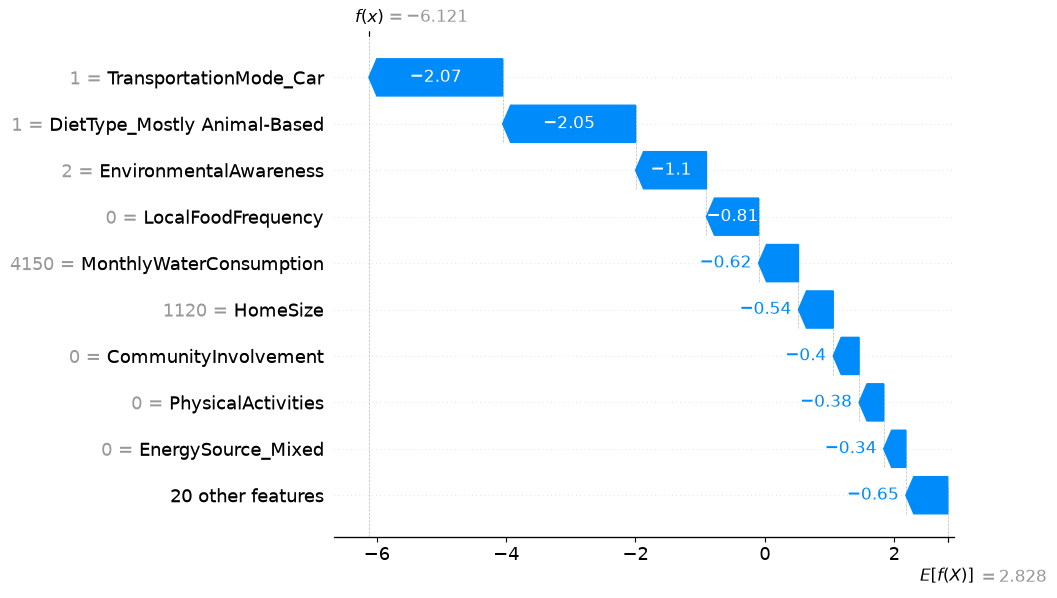

In [19]:
# Make sure you have an Explanation object from shap.Explainer
# shap_values = explainer(X_test)

# Pick an instance index to explain, e.g., the first test sample
i = 0

# Plot waterfall for that instance (for positive class)
shap.plots.waterfall(shap_values[i])

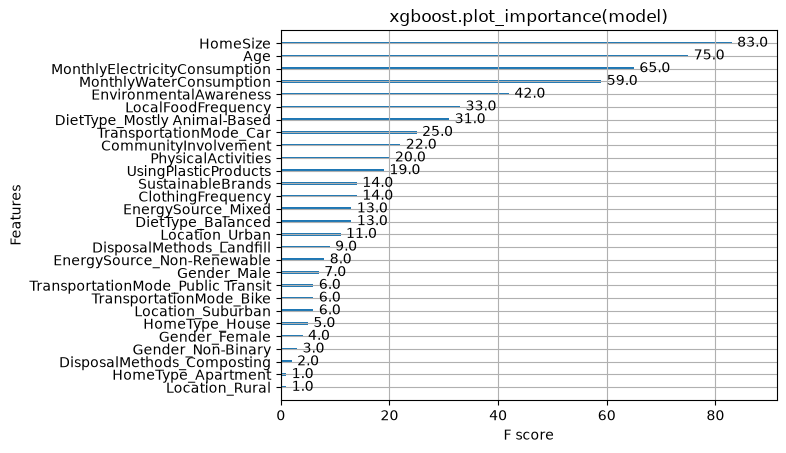

In [20]:
# XGBoost has a built-in importance feature too
xgb.plot_importance(model)
plt.title("xgboost.plot_importance(model)")
plt.show()

In [21]:
# Make sure to initialize JS visualization (for notebooks)
shap.initjs()

# Select an instance index to explain, e.g., first test sample
i = 0

# Create the force plot
shap.plots.force(shap_values[i])


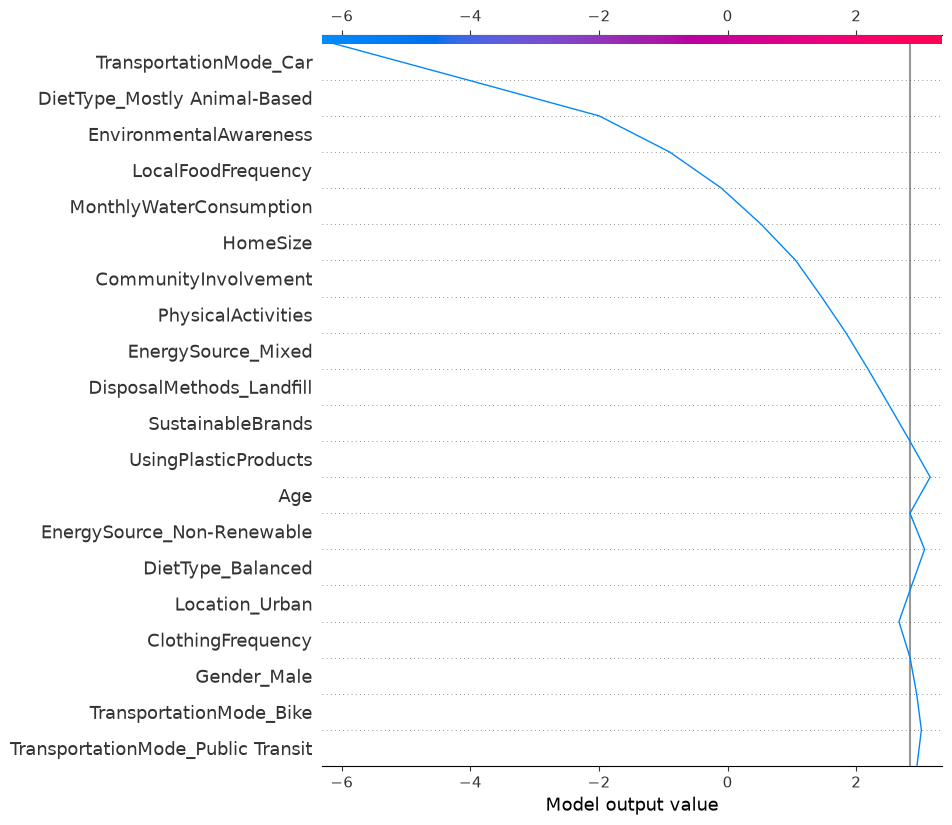

In [22]:
shap.plots.decision(
    base_value=shap_values.base_values[0],
    shap_values=shap_values.values[0],
    feature_names=list(X_test.columns)
)


**This plot looks promising, but might have bugs, not thoroughly tested**

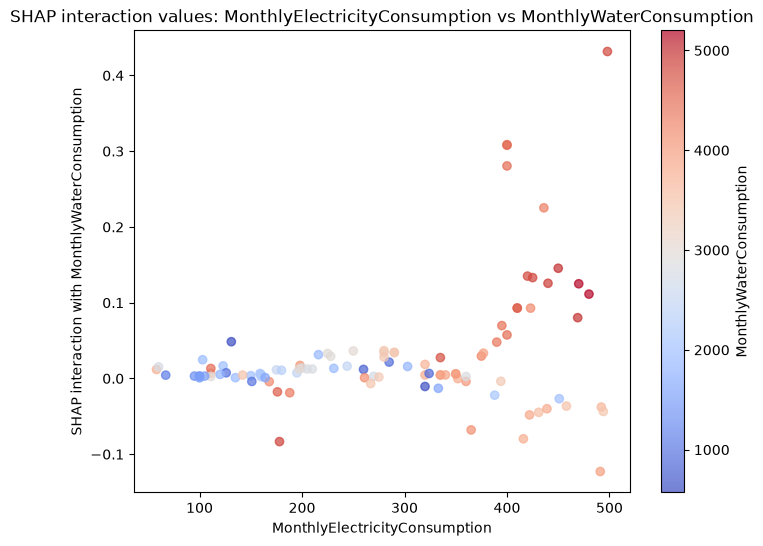

In [23]:
# a more simple version of the code above...
# needs still more testing if this actually works. 
# probably would be easiest to have a much more simple dataset
# and to test how it behaves here
import matplotlib.pyplot as plt

feature_1 = 'MonthlyElectricityConsumption'
feature_2 = 'MonthlyWaterConsumption'

explainer = shap.TreeExplainer(model)

shap_interaction_values = explainer.shap_interaction_values(X_test)

# Indices of the two features
i = X_test.columns.get_loc(feature_1)
j = X_test.columns.get_loc(feature_2)

# Extract values
interaction_vals = shap_interaction_values[:, i, j]
feat1_vals = X_test.iloc[:, i]
feat2_vals = X_test.iloc[:, j]

# Plot
plt.figure(figsize=(8, 6))
sc = plt.scatter(feat1_vals, interaction_vals, c=feat2_vals, cmap='coolwarm', alpha=0.7)
plt.xlabel(feature_1)
plt.ylabel('SHAP interaction with ' + feature_2)
plt.colorbar(sc, label=feature_2)
plt.title(f'SHAP interaction values: {feature_1} vs {feature_2}')
plt.show()


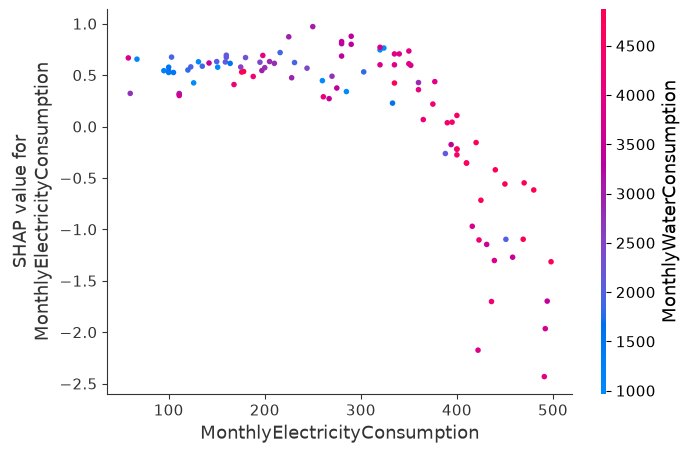

In [24]:
# a more simple version of the code above

# Example with TreeExplainer
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

# Then plot
shap.dependence_plot(
    feature_1,            # can be index or name
    shap_values,          # 2D array [n_samples, n_features]
    X_test,               # DataFrame or array with feature names
    interaction_index=feature_2  # optional
)
